In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import pandas as pd
from aqs import causal as C, features as F, plots as P, results as R
from aqs.config import CITIES, PROCESSED

pd.set_option("display.precision", 3)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 40)
P.use_theme()
long = F.load_long()

In [2]:
pd.concat([C.stationarity_table(long, role).assign(role=role) for role in R.ROLES]).pivot_table(
    index=["role", "city"], columns=["version", "series"], values="adf_p", sort=False)

version                    raw            season removed             \
series                   PM2.5  attention          PM2.5  attention   
role      city                                                        
attention bangkok    3.884e-03  5.242e-02      3.809e-18  1.057e-03   
          krakow     1.627e-02  7.502e-02      8.294e-19  2.870e-14   
          melbourne  4.067e-05  1.154e-09      2.234e-16  1.613e-05   
          lahore     1.241e-01  1.929e-04      1.381e-10  4.790e-07   
health    bangkok    3.884e-03        NaN      3.809e-18        NaN   
          krakow     1.627e-02        NaN      8.294e-19        NaN   
          melbourne  4.067e-05        NaN      2.234e-16        NaN   
          lahore     1.241e-01        NaN      1.381e-10        NaN   

version                    raw season removed  
series                  health         health  
role      city                                 
attention bangkok          NaN            NaN  
          krakow           NaN            NaN  
          melbourne        NaN            NaN  
          lahore           NaN            NaN  
health    bangkok    3.871e-16      3.156e-18  
          krakow     2.504e-04      5.499e-22  
          melbourne  1.384e-01      2.101e-15  
          lahore     6.652e-18      8.041e-21

In [3]:
tables = R.build(long)
tables["granger"]

,role,city,direction,lags,weeks,F,p,p_fdr,significant
0,attention,bangkok,PM2.5 → attention,1,148,0.026,0.871,0.929,False
1,attention,bangkok,PM2.5 → attention,2,146,0.186,0.831,0.927,False
2,attention,bangkok,PM2.5 → attention,3,144,0.526,0.665,0.927,False
3,attention,bangkok,PM2.5 → attention,4,142,0.892,0.471,0.886,False
4,attention,bangkok,attention → PM2.5 (placebo),1,148,0.333,0.565,0.927,False
5,attention,bangkok,attention → PM2.5 (placebo),2,146,3.674,0.028,0.185,False
6,attention,bangkok,attention → PM2.5 (placebo),3,144,3.576,0.016,0.185,False
7,attention,bangkok,attention → PM2.5 (placebo),4,142,2.841,0.027,0.185,False
8,attention,krakow,PM2.5 → attention,1,128,3.849,0.052,0.185,False
9,attention,krakow,PM2.5 → attention,2,122,2.350,0.100,0.291,False


In [4]:
tables["granger"].pivot_table(index=["role", "city", "direction"], columns="lags", values="p_fdr", sort=False)

lags                                                 1      2      3      4
role      city      direction                                              
attention bangkok   PM2.5 → attention            0.929  0.927  0.927  0.886
                    attention → PM2.5 (placebo)  0.927  0.185  0.185  0.185
          krakow    PM2.5 → attention            0.185  0.291  0.291  0.667
                    attention → PM2.5 (placebo)  0.927  0.984  0.185  0.495
          melbourne PM2.5 → attention            0.927  0.927  0.927  0.927
                    attention → PM2.5 (placebo)  0.532  0.927  0.927  0.988
          lahore    PM2.5 → attention            0.185  0.901  0.304  0.343
                    attention → PM2.5 (placebo)  0.927  0.185  0.185  0.185
health    bangkok   PM2.5 → health               0.693  0.417  0.693  0.693
                    health → PM2.5 (placebo)     0.298  0.417  0.298  0.298
          krakow    PM2.5 → health               0.938  0.837  0.837  0.837
                    health → PM2.5 (placebo)     0.938  0.837  0.841  0.938
          melbourne PM2.5 → health               0.938  0.995  0.995  0.995
                    health → PM2.5 (placebo)     0.837  0.837  0.837  0.514
          lahore    PM2.5 → health               0.837  0.837  0.912  0.938
                    health → PM2.5 (placebo)     0.938  0.841  0.952  0.995

In [5]:
tables["forecast_skill"].set_index(["role", "city"]).drop(columns="series").sort_index(level="role", sort_remaining=False).T

role              attention                                  health  \
city                bangkok     krakow  melbourne lahore    bangkok   
weeks                   142        110         86     83        142   
r2_calendar           0.284       0.42     -0.341  0.109     -0.385   
mae_calendar          0.385      0.457      0.574  0.501      0.902   
r2_calendar_pm25      0.429       0.38     -0.325  0.128     -0.295   
mae_calendar_pm25     0.344      0.463      0.572  0.506      0.853   
r2_gain_from_pm25     0.144      -0.04      0.016  0.019       0.09   
r2_depth2             0.422      0.376     -0.323  0.128     -0.257   
r2_depth4             0.429       0.38     -0.325  0.128     -0.295   
r2_depth6              0.43       0.38     -0.325  0.128      -0.31   
importance_pm25       0.972      0.367      0.562  0.872       0.82   
top_feature            pm25  month_cos  month_sin   pm25  pm25_lag2   

role                                            
city                  krakow  melbourne lahore  
weeks                    110         86     83  
r2_calendar            0.041      -0.11 -0.123  
mae_calendar            0.74      0.783  0.811  
r2_calendar_pm25       0.039     -0.189 -0.153  
mae_calendar_pm25       0.74      0.824  0.813  
r2_gain_from_pm25     -0.002     -0.079  -0.03  
r2_depth2              0.056     -0.184 -0.123  
r2_depth4              0.039     -0.189 -0.153  
r2_depth6              0.035     -0.191 -0.155  
importance_pm25        0.763      0.728  0.865  
top_feature        pm25_lag3  month_cos   pm25

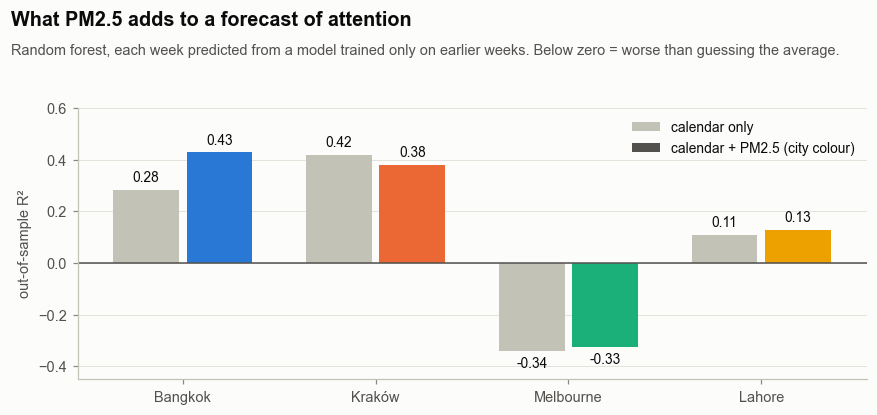

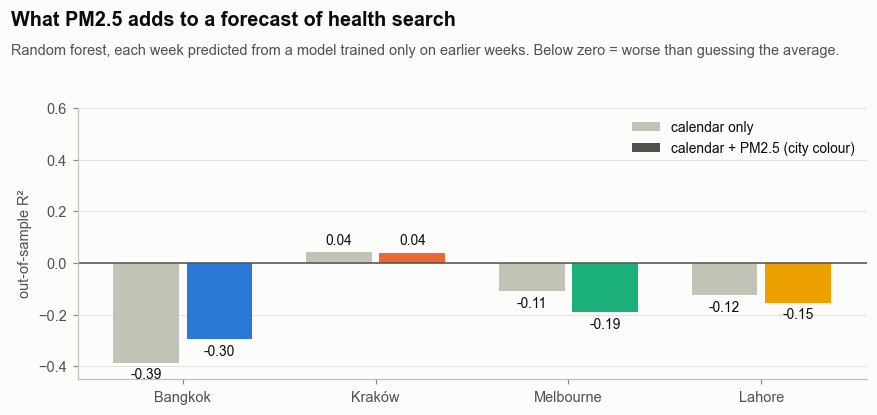

In [6]:
for role in R.ROLES:
    P.forecast_skill_plot(tables["forecast_skill"][tables["forecast_skill"]["role"] == role].set_index("city"), role)

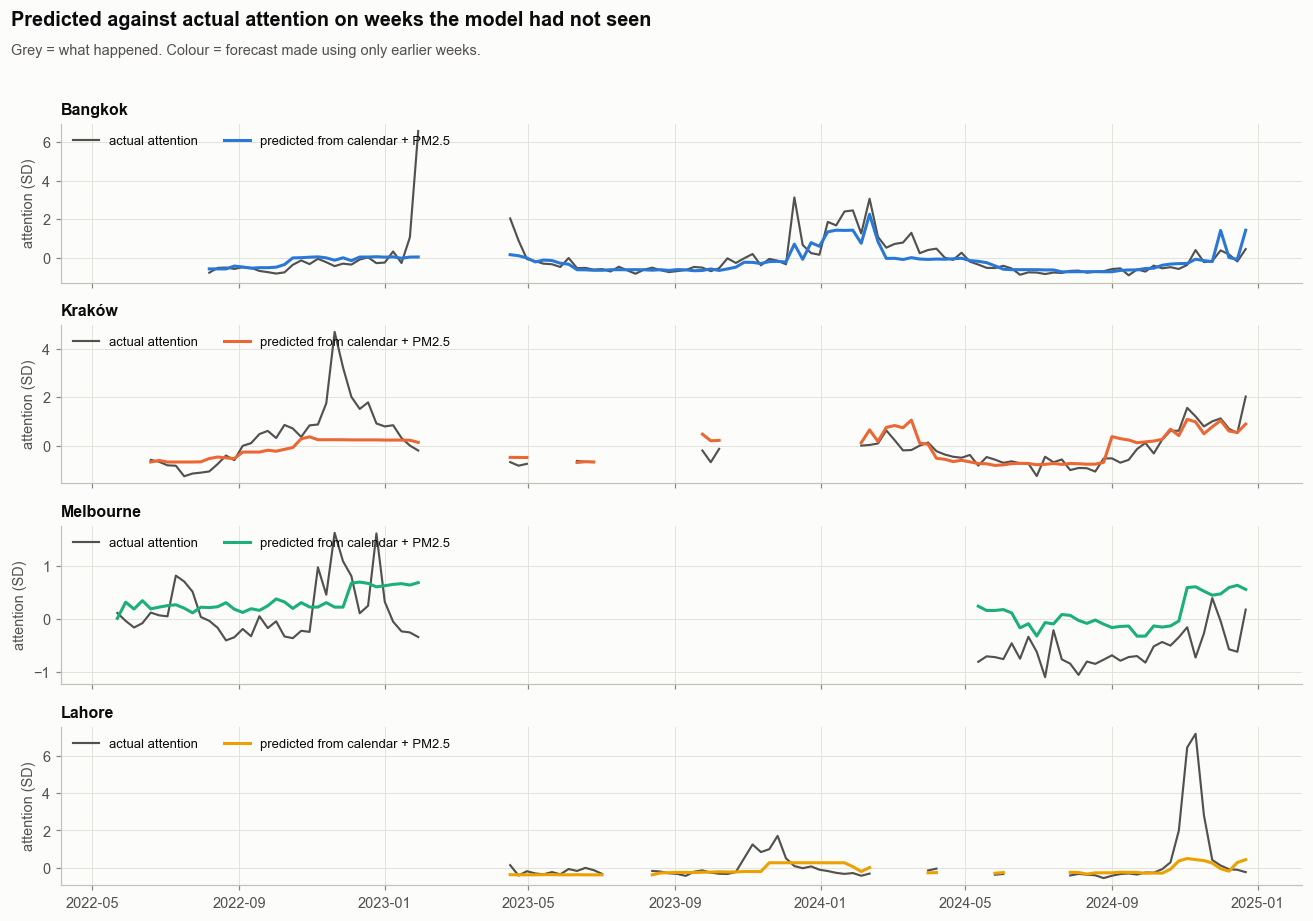

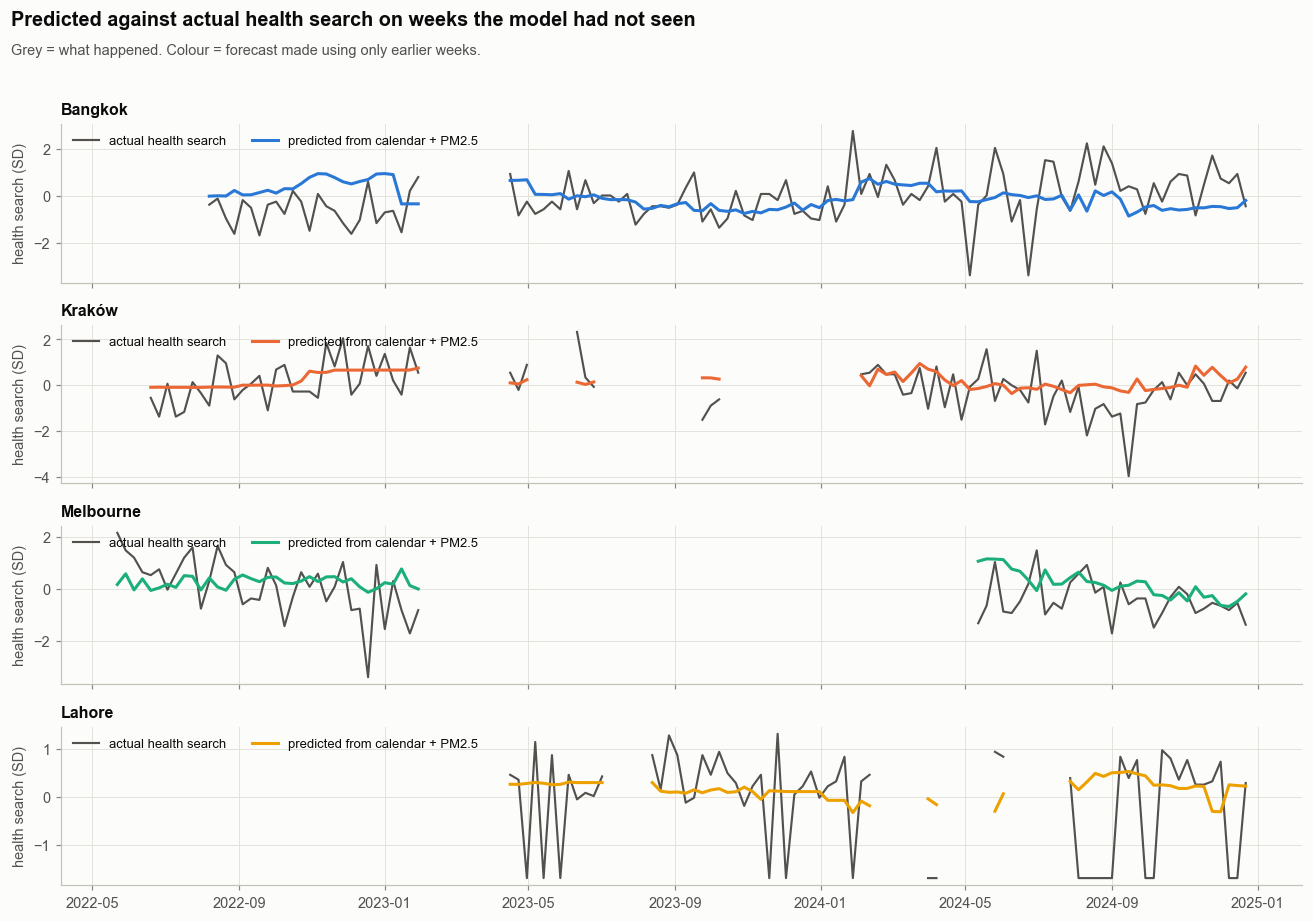

In [7]:
for role in R.ROLES:
    P.forecast_timeline(tables["predictions"][role], role)

In [8]:
skill = C.series_skill(long)
skill

,city,series,role,weeks,r2_calendar,r2_calendar_pm25,r2_gain_from_pm25,term,geo_level
0,bangkok,attention index (PC1),attention,142,0.284,0.429,1.443e-01,NaN,NaN
1,bangkok,"air purifier (English, country)",protection,142,0.288,0.367,7.877e-02,air_purifier,country
2,bangkok,"air quality (English, country)",awareness,142,0.231,0.328,9.727e-02,air_quality,country
3,bangkok,breathing difficulty (Thai),health,142,-0.383,-0.294,8.954e-02,breathing_difficulty_th,country
4,bangkok,"chest pain (English, country)",health,142,-0.371,-0.439,-6.845e-02,chest_pain,country
5,bangkok,chest pain (Thai),health,142,-0.137,-0.087,5.037e-02,chest_pain_th,country
6,bangkok,cough medicine (Thai),health,142,-0.846,-0.744,1.024e-01,cough_medicine_th,country
7,bangkok,"eye drops (English, country)",health,142,-0.974,-0.963,1.074e-02,eye_drops,country
8,bangkok,eye drops (Thai),health,142,-1.675,-1.578,9.660e-02,eye_drops_th,country
9,bangkok,"hospital (English, country)",health,142,-0.754,-0.574,1.801e-01,hospital,country


In [9]:
skill.groupby(["city", "role"], sort=False)[["r2_calendar", "r2_calendar_pm25", "r2_gain_from_pm25"]].median()

r2_calendar  r2_calendar_pm25  r2_gain_from_pm25
city      role                                                        
bangkok   attention         0.284             0.429              0.144
          protection        0.218             0.323              0.091
          awareness         0.220             0.373              0.177
          health           -0.800            -0.659              0.093
krakow    attention         0.420             0.380             -0.040
          protection        0.314             0.261             -0.053
          awareness         0.146             0.299              0.152
          health           -0.105            -0.110              0.061
melbourne attention        -0.341            -0.325              0.016
          protection       -1.047            -0.928             -0.131
          awareness        -0.379            -0.391             -0.012
          health           -0.110            -0.190             -0.089
lahore    attention         0.109             0.128              0.019
          protection       -0.087            -0.147             -0.061
          awareness         0.153             0.173              0.020
          health           -0.124            -0.154             -0.030

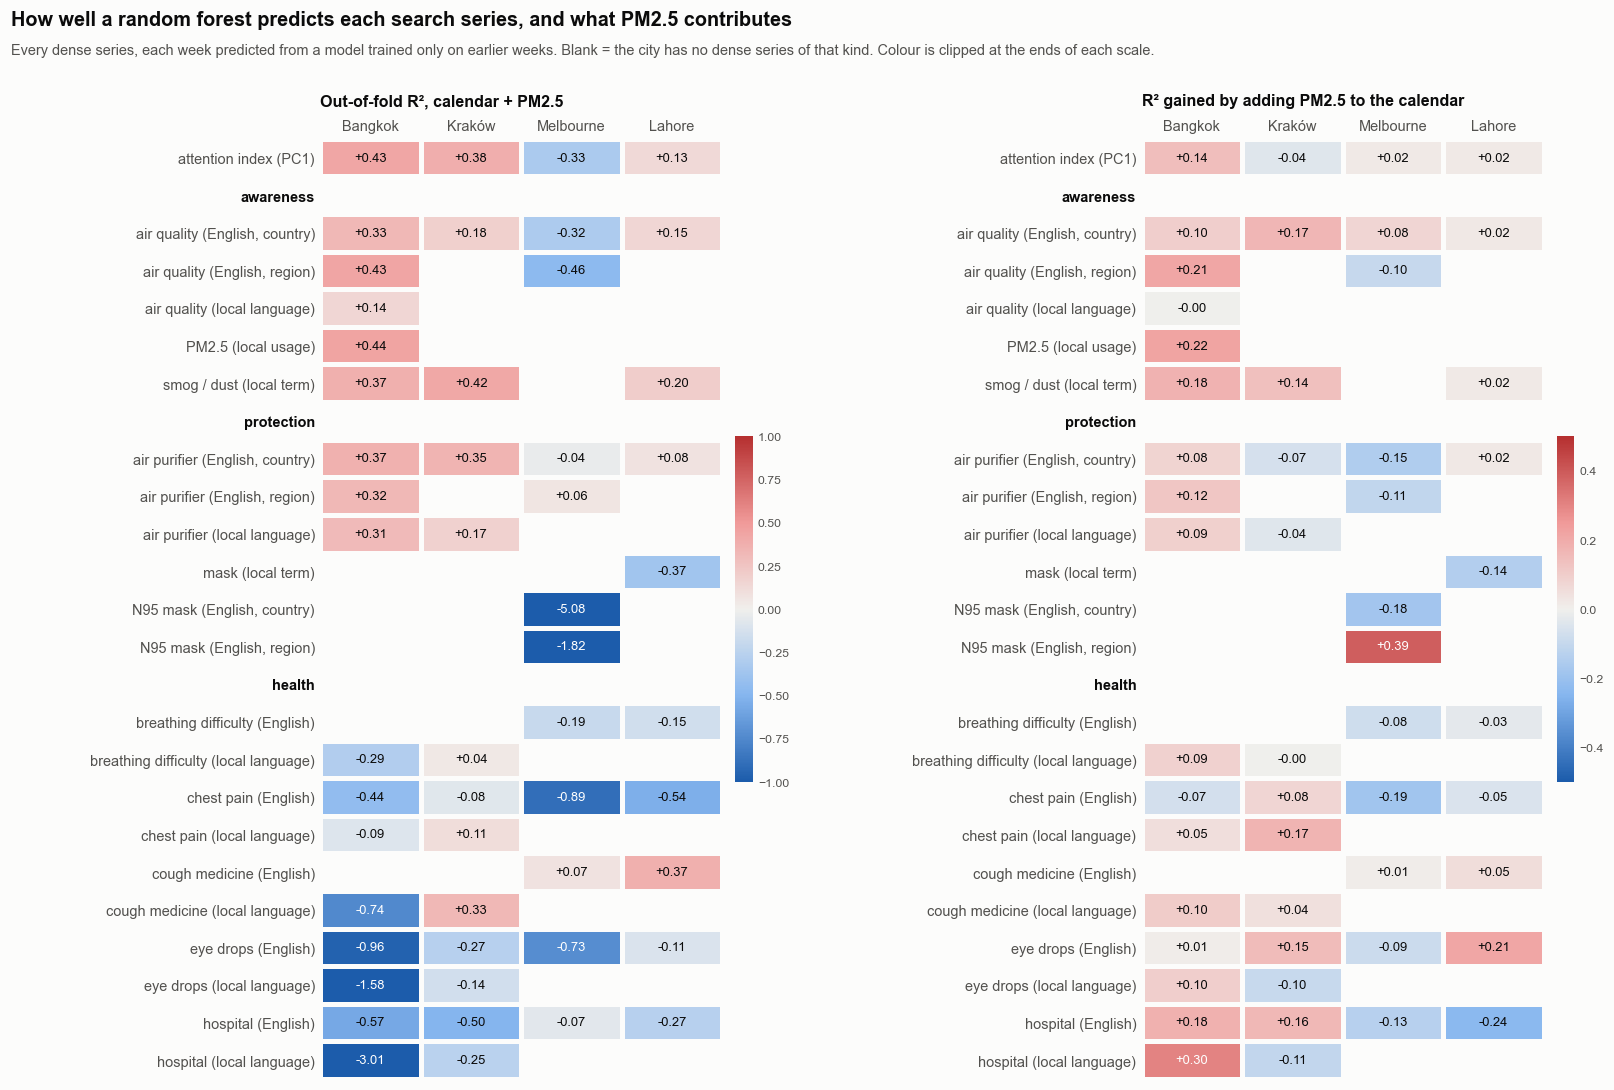

In [10]:
P.rf_r2_heatmap(skill);

In [11]:
R.write(tables);

results_summary.csv: 52 rows
awareness_scorecard.csv: 8 rows
verdicts.csv: 8 rows


In [12]:
card = pd.read_csv(PROCESSED / "awareness_scorecard.csv")
print(card.shape, list(card.columns[:3]))
card.set_index(["city", "role", "series"]).round(2).T

(8, 26) ['city', 'role', 'series']


city                               bangkok                              \
role                             attention                      health   
series               attention index (PC1) breathing difficulty (Thai)   
surprise_effect                       0.66                       -0.02   
surprise_p                            0.00                        0.91   
expected_effect                       0.75                        0.09   
expected_p                            0.00                        0.54   
threshold                            21.91                       34.67   
threshold_low                        12.93                       12.44   
threshold_high                       34.95                       39.28   
threshold_aic_gain                    1.82                        0.59   
episodes                              6.00                        6.00   
peak_week                             1.00                        0.00   
peak_response                         0.97                        0.72   
peak_low                             -0.62                       -0.56   
peak_high                             3.39                        1.96   
weeks_to_half                         1.00                        2.00   
habituation_per_week                  0.07                       -0.04   
habituation_p                         0.00                        0.14   
habituation_loso_min                  0.05                       -0.05   
habituation_loso_max                  0.09                       -0.02   
silent_share                          0.02                        0.50   
silent_low                            0.00                        0.42   
silent_high                           0.06                        0.64   
silent_early                          0.04                        0.43   
silent_late                           0.00                        0.56   

city                                krakow                                \
role                             attention                        health   
series               attention index (PC1) breathing difficulty (Polish)   
surprise_effect                       0.46                         -0.05   
surprise_p                            0.00                          0.68   
expected_effect                       1.11                          0.60   
expected_p                            0.00                          0.00   
threshold                             8.04                          8.04   
threshold_low                         7.66                          7.19   
threshold_high                       18.15                         21.94   
threshold_aic_gain                   -2.01                         -2.25   
episodes                              6.00                          6.00   
peak_week                             0.00                          6.00   
peak_response                         0.54                          0.24   
peak_low                             -0.43                         -0.23   
peak_high                             1.90                          0.87   
weeks_to_half                         1.00                          1.00   
habituation_per_week                 -0.05                          0.04   
habituation_p                         0.01                          0.13   
habituation_loso_min                 -0.12                         -0.01   
habituation_loso_max                 -0.04                          0.06   
silent_share                          0.09                          0.33   
silent_low                            0.02                          0.24   
silent_high                           0.20                          0.47   
silent_early                          0.05                          0.45   
silent_late                           0.12                          0.24   

city                             melbourne  \
role                             attention   
series

In [13]:
verdict = pd.read_csv(PROCESSED / "verdicts.csv")
print(verdict.shape, list(verdict.columns[:3]))
verdict.set_index(["city", "role", "series"]).round(3).T

(8, 12) ['city', 'role', 'series']


city                                    bangkok                              \
role                                  attention                      health   
series                    attention index (PC1) breathing difficulty (Thai)   
deseason_r                                0.528                      -0.011   
correlation_survives                       True                       False   
granger_forward_min_p_fdr                 0.886                       0.417   
granger_forward                           False                       False   
granger_placebo_min_p_fdr                 0.185                       0.298   
granger_placebo                           False                       False   
r2_gain_from_pm25                         0.144                        0.09   
silent_share                               0.02                         0.5   
habituation_per_week                       0.07                      -0.039   

city                                     krakow                                \
role                                  attention                        health   
series                    attention index (PC1) breathing difficulty (Polish)   
deseason_r                                0.582                        -0.039   
correlation_survives                       True                         False   
granger_forward_min_p_fdr                 0.185                         0.837   
granger_forward                           False                         False   
granger_placebo_min_p_fdr                 0.185                         0.837   
granger_placebo                           False                         False   
r2_gain_from_pm25                         -0.04                        -0.002   
silent_share                              0.089                         0.333   
habituation_per_week                     -0.051                         0.039   

city                                  melbourne  \
role                                  attention   
series                    attention index (PC1)   
deseason_r                                 0.07   
correlation_survives                      False   
granger_forward_min_p_fdr                 0.927   
granger_forward                           False   
granger_placebo_min_p_fdr                 0.532   
granger_placebo                           False   
r2_gain_from_pm25                         0.016   
silent_share                                0.5   
habituation_per_week                     -0.051   

city                                                               \
role                                                       health   
series                    breathing difficulty (English, country)   
deseason_r                                                  0.203   
correlation_survives                                        False   
granger_forward_min_p_fdr                                   0.938   
granger_forward                                             False   
granger_placebo_min_p_fdr                                   0.514   
granger_placebo                                             False   
r2_gain_from_pm25                                          -0.079   
silent_share                                                0.375   
habituation_per_week                                        0.028   

city                                     lahore  \
role                                  attention   
series                    attention index (PC1)   
deseason_r                                0.587   
correlation_survives                       True   
granger_forward_min_p_fdr                 0.185   
granger_forward                           False   
granger_placebo_min_p_fdr                 0.185   
granger_placebo                           False   
r2_gain_from_pm25                         0.019   
silent_share                              0.171   
habituation_per_week                     -0.091   

city                   